In [1]:
import json
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping


2025-05-14 20:02:04.918101: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 20:02:04.918125: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
print(df['Attack_type'].value_counts())

Attack_type
Normal                   1399624
DDoS_UDP                  121567
DDoS_ICMP                  67939
SQL_injection              50826
DDoS_TCP                   50062
Vulnerability_scanner      50026
Password                   49933
DDoS_HTTP                  48544
Uploading                  36957
Backdoor                   24026
Port_Scanning              19977
XSS                        15068
Ransomware                  9689
Fingerprinting               853
MITM                         358
Name: count, dtype: int64


In [6]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [7]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [8]:
print(df['Attack_type'].value_counts())

Attack_type
0     1399624
13     121567
14      67939
4       50826
6       50062
9       50026
7       49933
5       48544
2       36957
10      24026
8       19977
11      15068
3        9689
12        853
1         358
Name: count, dtype: int64


In [9]:
mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=42)
mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

In [10]:
# Print top features
print(mi_scores.head(10))

tcp.dstport      0.870595
dns_0            0.788073
tcp.ack_raw      0.745540
tcp.ack          0.722140
mqtt3_0          0.653018
mqtt1_0          0.652799
mqtt2_0          0.652175
http3_encoded    0.622944
http1_encoded    0.609375
dns_encoded      0.606070
dtype: float64


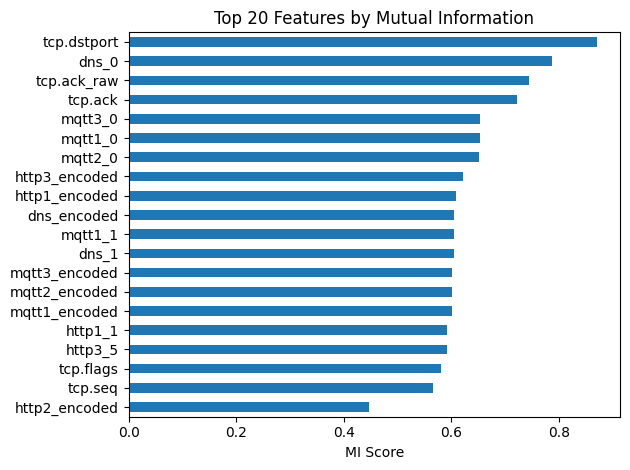

In [11]:
mi_scores.head(20).plot(kind='barh')
plt.title("Top 20 Features by Mutual Information")
plt.xlabel("MI Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

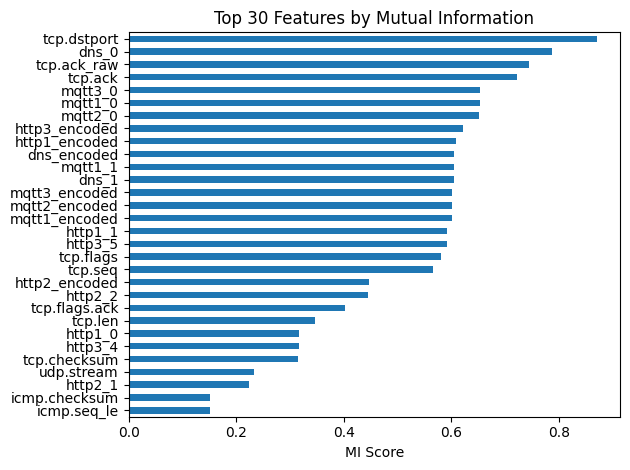

In [12]:
mi_scores.head(30).plot(kind='barh')
plt.title("Top 30 Features by Mutual Information")
plt.xlabel("MI Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

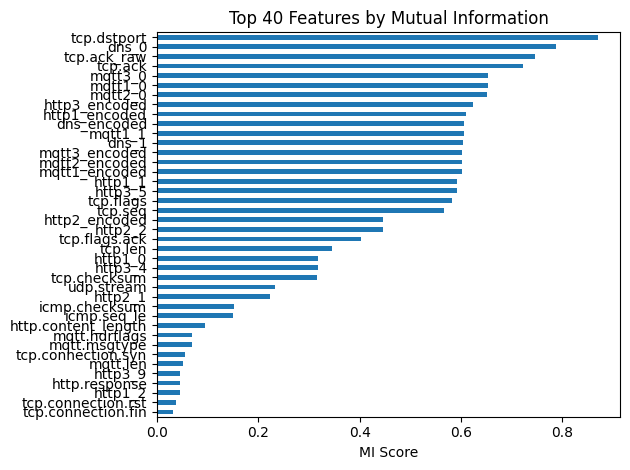

In [13]:
mi_scores.head(40).plot(kind='barh')
plt.title("Top 40 Features by Mutual Information")
plt.xlabel("MI Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [14]:
best_params = {
    "filters": 0,
    "kernel_size": 0,
    "dropout_rate": 0,
    "learning_rate": 0,
    "l2_reg": 0,
}

best_fit_params = {
    "batch_size": 32,
    "epochs": 25,
}

In [15]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=15,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=0.0,
):
    _model = Sequential([
        Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation="relu",
               kernel_regularizer=l2(l2_reg),
               input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

In [16]:
max_features = len(mi_scores)
feature_counts = list(range(10, max_features + 1, 10))  # e.g., 10, 20, ..., up to all features

results = []
num_classes = 15
for k in feature_counts:
    selected_features = mi_scores.head(k).index.tolist()
    X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

    class_weights = class_weight.compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train),
        y=y_train
    )
    # Build the class_weight dictionary
    class_weights_dict = {
        int(cls): weight for cls, weight in zip(np.unique(y_train), class_weights)
    }
    scaler = StandardScaler().fit(X_train)
    X_train = scaler.transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)
    input_shape = (X_train.shape[1], 1)
    model = model_1d_cnn(input_shape=input_shape,
                     num_classes=num_classes)
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=best_fit_params['epochs'],
                        batch_size=best_fit_params['batch_size'],
                        callbacks=[early_stop],
                        class_weight=class_weights_dict,)
    val_acc = max(history.history['val_accuracy'])
    results.append((k, val_acc))

2025-05-14 20:24:52.548974: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-14 20:24:52.552145: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 20:24:52.552236: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-05-14 20:24:52.552300: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-05-14 20:24:52.552373: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Epoch 1/25
42557/42557 [==============================] - 90s 2ms/step - loss: 1.1804 - accuracy: 0.8306 - val_loss: 0.3168 - val_accuracy: 0.8498
Epoch 2/25
42557/42557 [==============================] - 88s 2ms/step - loss: 1.0215 - accuracy: 0.8474 - val_loss: 0.2920 - val_accuracy: 0.8418
Epoch 3/25
42557/42557 [==============================] - 89s 2ms/step - loss: 0.9968 - accuracy: 0.8486 - val_loss: 0.3098 - val_accuracy: 0.8569
Epoch 4/25
42557/42557 [==============================] - 90s 2ms/step - loss: 0.9861 - accuracy: 0.8505 - val_loss: 0.3101 - val_accuracy: 0.8552
Epoch 5/25
42557/42557 [==============================] - 90s 2ms/step - loss: 1.0147 - accuracy: 0.8496 - val_loss: 0.3128 - val_accuracy: 0.8446
Epoch 6/25
42557/42557 [==============================] - 89s 2ms/step - loss: 1.0095 - accuracy: 0.8486 - val_loss: 0.3307 - val_accuracy: 0.8121
Epoch 7/25
42557/42557 [==============================] - 91s 2ms/step - loss: 1.0196 - accuracy: 0.8486 - val_loss: 0

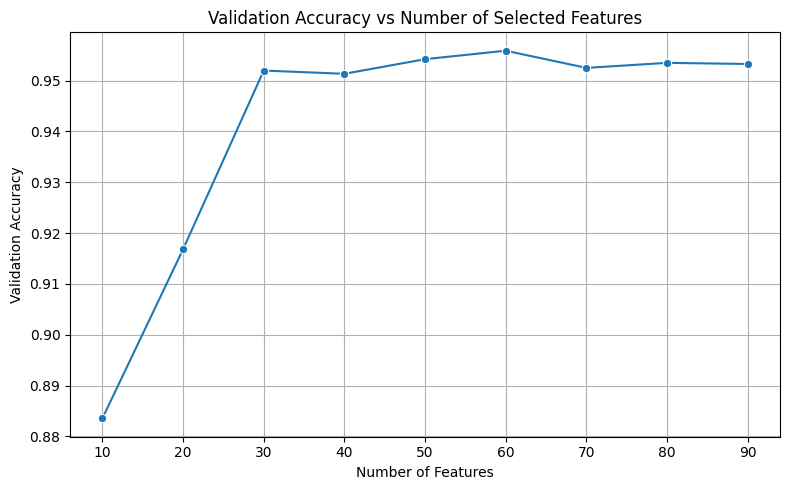

In [17]:
results_df = pd.DataFrame(results, columns=['num_features', 'val_accuracy'])
plt.figure(figsize=(8,5))
sns.lineplot(data=results_df, x='num_features', y='val_accuracy', marker='o')
plt.title("Validation Accuracy vs Number of Selected Features")
plt.xlabel("Number of Features")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
results_df

,num_features,val_accuracy
0,10,0.883549
1,20,0.916821
2,30,0.951980
3,40,0.951343
4,50,0.954221
5,60,0.955887
6,70,0.952510
7,80,0.953497
8,90,0.953276


In [19]:
# Convert to list of dicts
results_dict = results_df.to_dict(orient='records')

# Save to local hard drive (same folder as script, or change path as needed)
output_path = 'results/FI/results_mi_weighted_tuning.json'

with open(output_path, 'w') as f:
    json.dump(results_dict, f, indent=4)